# 8. Error Analysis 

## Purpose
Find where and how confidently the tuned model is wrong, using training data only. 

This notebook should be skipped for regression problems.

## Inputs
- `data/processed/` — final preprocessed training data
- `config.yaml` — threshold metric and number of thresholds
- `artifacts/tuned_models.pkl` — tuned models from notebook 5
- `artifacts/threshold.pkl` — tuned models from notebook 6
- `data/processed/` — for grouping column

## Outputs
- `reports/error_analysis.csv`
- `reports/figures/error_by_confidence.png` 


## Decisions for the user
- Set group_column, confident_margin and confidence_bins in config.yaml


## Important note
Errors are studied on out-of-fold training predictions; the test set is not used

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from src.config.settings import load_config
from src.config.paths import (
    PROCESSED_DATA_DIR,
    ARTIFACTS_DIR,
    TUNED_MODELS_DIR,
    REPORTS_DIR,
    FIGURES_DIR,
)
from src.data.load_data import load_raw_data
from src.models.training.threshold_tuning import tune_threshold, compute_threshold_curves
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from src.analysis.error_analysis import build_error_table, error_rate_by_bands, confident_errors, aligned_column
from sklearn.base import clone

## 1. Load config

In [2]:
config = load_config()

TARGET = config["target"]
DROP_COLS = config["drop_columns"]
SPLIT_CONFIG = config["split"]
TUNING_CONFIG = config["tuning"]
THRESHOLD_CONFIG = config["threshold_tuning"]
ERROR_CONFIG = config["error_analysis"]

print(f"Target:           {TARGET}")
print(f"Grouping column:  {ERROR_CONFIG['group_column']}")
print(f"Confident margin: {ERROR_CONFIG['confident_margin']}")

Target:           good
Grouping column:  quality
Confident margin: 0.2


## 2. Load processed data


In [3]:
X_train = pd.read_csv(PROCESSED_DATA_DIR / "X_train.csv")
y_train = pd.read_csv(PROCESSED_DATA_DIR / "y_train.csv").squeeze()

print(f"X_train shape: {X_train.shape}")

X_train shape: (1087, 11)


## 3. Check task type
Threshold tuning only applies to classification problems. This cell
confirms the task type and exits for regression problems.

In [4]:
baseline_trainer = joblib.load(ARTIFACTS_DIR / "baseline_trainer.pkl")
task = baseline_trainer.task_

print(f"Task: {task}")

# Skip threshold tuning for regression

if task == "regression":
    print("Threshold tuning is not applicable for regression problems.")
    print("Proceeding to final evaluation.")
else:
    print("Classification task detected — proceeding with error analysis.")

Task: classification
Classification task detected — proceeding with error analysis.


## 4. Load tuned models


In [5]:
tuned_models = joblib.load(ARTIFACTS_DIR / "tuned_models.pkl")
print(f"Available tuned models: {list(tuned_models.keys())}")

model_name = TUNING_CONFIG["models_to_tune"][0]
model = tuned_models[model_name]

threshold_artifact = joblib.load(ARTIFACTS_DIR / "threshold.pkl")
threshold = threshold_artifact["optimal_threshold"]

print(f"Analysing errors for: {model_name}")
print(f"Using threshold:      {threshold:.2f} (tuned on {threshold_artifact['metric']})")

Available tuned models: ['xgboost_classifier', 'logistic_regression']
Analysing errors for: xgboost_classifier
Using threshold:      0.40 (tuned on f1)


## 5. Out of Fold Predictions


In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SPLIT_CONFIG["random_state"])
model_cv = clone(model).set_params(n_jobs=config["n_jobs"])
y_proba_train = cross_val_predict(model_cv, X_train, y_train, cv=cv,
                                  method="predict_proba")[:, 1]

print(f"Out-of-fold probabilities computed: shape {y_proba_train.shape}")   

Out-of-fold probabilities computed: shape (1087,)


## 6. Error Table


In [7]:
table = build_error_table(y_train, y_proba_train, threshold)

print(f"Wrong predictions: {table['wrong'].sum()} of {len(table)} "
      f"({table['wrong'].mean():.1%})")
table.head()

Wrong predictions: 282 of 1087 (25.9%)


,true,proba,pred,wrong
0,1,0.876027,1,False
1,1,0.806481,1,False
2,0,0.563307,1,True
3,1,0.912890,1,False
4,0,0.664497,1,True


## 7. Error Rate by Confidence Band

In [8]:
bands = error_rate_by_bands(table, ERROR_CONFIG["confidence_bins"])
bands

,error_rate,n
band,,
"(-0.001, 0.2]",0.130719,153
"(0.2, 0.35]",0.257282,206
"(0.35, 0.5]",0.493827,162
"(0.5, 0.65]",0.448529,136
"(0.65, 0.8]",0.268156,179
"(0.8, 1.0]",0.079681,251


## 8. Error Rate by Grouping 

In [9]:
group_col = ERROR_CONFIG["group_column"]

if group_col is None:
    print("No grouping column set in config. Skipping.")
else:
    raw_df = load_raw_data(na_values=config.get("na_values", []))
    group_values = aligned_column(raw_df, config, group_col)
    assert len(group_values) == len(table), "Grouping column does not line up with the training rows"
    table[group_col] = group_values.values

    by_group = table.groupby(group_col)["wrong"].agg(["sum", "mean", "count"])
    by_group = by_group.rename(columns={"sum": "errors", "mean": "error_rate", "count": "n"})
    by_group["share_of_errors"] = by_group["errors"] / by_group["errors"].sum()
    display(by_group)

0 instances have been dropped


,errors,error_rate,n,share_of_errors
quality,,,,
3,0,0.000000,7,0.000000
4,18,0.450000,40,0.063830
5,178,0.382796,465,0.631206
6,84,0.193103,435,0.297872
7,2,0.015504,129,0.007092
8,0,0.000000,11,0.000000


In [10]:
group_col = ERROR_CONFIG["group_column"]

if group_col is None:
    print("No grouping column set in config. Skipping.")
else:
    raw_df = load_raw_data(na_values=config.get("na_values", []))
    group_values = aligned_column(raw_df, config, group_col)
    assert len(group_values) == len(table), "Grouping column does not line up with the training rows"
    table[group_col] = group_values.values

    by_group = table.groupby(group_col)["wrong"].agg(["sum", "mean", "count"])
    by_group = by_group.rename(columns={"sum": "errors", "mean": "error_rate", "count": "n"})
    by_group["share_of_errors"] = by_group["errors"] / by_group["errors"].sum()
    display(by_group)

0 instances have been dropped


,errors,error_rate,n,share_of_errors
quality,,,,
3,0,0.000000,7,0.000000
4,18,0.450000,40,0.063830
5,178,0.382796,465,0.631206
6,84,0.193103,435,0.297872
7,2,0.015504,129,0.007092
8,0,0.000000,11,0.000000


In [11]:
by_group.head()

,errors,error_rate,n,share_of_errors
quality,,,,
3,0,0.000000,7,0.000000
4,18,0.450000,40,0.063830
5,178,0.382796,465,0.631206
6,84,0.193103,435,0.297872
7,2,0.015504,129,0.007092


## 9. Confident Errors  

In [12]:
confident = confident_errors(table, ERROR_CONFIG["confident_margin"])
print(f"Confident errors: {len(confident)} of {len(table)} wines "
      f"({len(confident) / len(table):.1%})")

if group_col is not None:
    display(confident.groupby(group_col).size().rename("n"))

Confident errors: 40 of 1087 wines (3.7%)


quality
5    20
6    20
Name: n, dtype: int64

## 10. Save Outputs

In [13]:
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
table.to_csv(REPORTS_DIR / "error_analysis.csv", index=False)
print(f"Saved {len(table)} rows to {REPORTS_DIR / 'error_analysis.csv'}")

Saved 1087 rows to /home/kigr/wine-quality/reports/error_analysis.csv


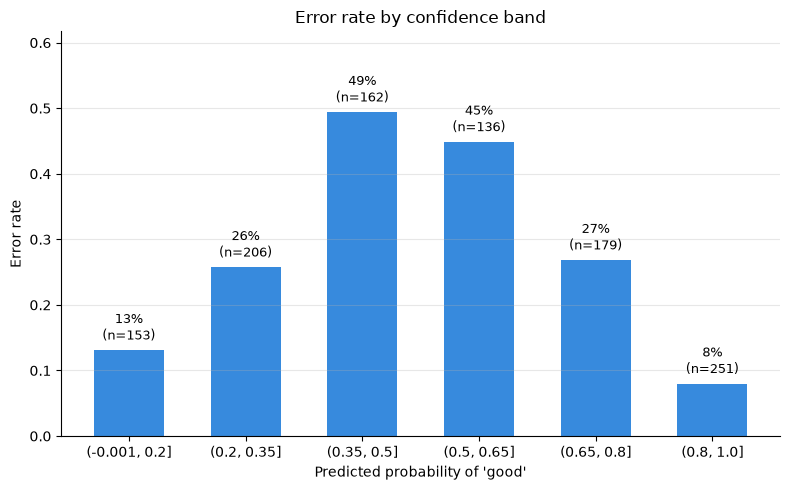

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))

labels = bands.index.astype(str)
bars = ax.bar(labels, bands["error_rate"], color="#378ADD", width=0.6, edgecolor="none")

for bar, rate, n in zip(bars, bands["error_rate"], bands["n"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{rate:.0%}\n(n={n})",
        ha="center", va="bottom", fontsize=9,
    )

ax.set_xlabel("Predicted probability of 'good'")
ax.set_ylabel("Error rate")
ax.set_title("Error rate by confidence band")
ax.set_ylim(0, max(bands["error_rate"]) * 1.25)
ax.grid(axis="y", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURES_DIR / "error_by_confidence.png", dpi=150, bbox_inches="tight")
plt.show()

282 wrong calls at the tuned threshold of 0.4 which is 26% of the training wines. The error rate decreases at either end of the scale to 8-13% with the middle bands at 45–49%. Moving the threshold from 0.5 to 0.40 shifted errors from the 6s to the 5s (48 fewer, 60 more) and added 15 overall.
Qualities 5 and 6 hold 262 of the 282 errors (93%), and the 4s only 18 
The model’s probabilities are honest: the error rate in each band roughly matches its stated probability with only 40 confident errors (3.7%) all of them quality 5 or 6.
The labels at tasters 5 and 6 may be nearly the same wine and this is consistent with even the confident errors being one point from the cut.
Next idea: predict the original quality score (3 to 8) as a number, then apply the cut at 6 afterwards, so the model keeps information the yes/no label throws away. Compare it using the same cross-validation, treating differences under about 0.005 AUC as noise.